<h1 align="center"><b>Flower Classification by Self-Supervised Learning (DINOv2)</b></h1>


## 📋 Table of Contents
1. [⚙️ Global Configuration](#config)
2. [📦 Setup & Imports](#setup)
3. [📊 Task 1 — Dataset EDA & Augmentation Visualisation](#eda)
4. [🟢 Task 3 — DINO: Model Definition](#dino-model)
5. [🏋️ Task 3 — DINO: Pre-Training Loop](#dino-train)
6. [📈 Task 3 — DINO: Training Curve](#dino-curve)
7. [👁️ Task 3 — DINO: Attention Map Visualisation](#dino-attn)
8. [🔬 Task 4 — Linear Probing with DINO Backbone](#linear-probe)
9. [🔍 Task 4 — k-NN Evaluation with DINO Backbone](#knn)
11. [🏁 Conclusion](#conclusion)
12. [📚 References](#references)

## ⚙️ Global Configuration <a id='config'></a>

**All hyperparameters and toggles are centralized here.**

In [1]:
import os
import re
import timm

# ╔══════════════════════════════════════════════════════════════════╗
# ║         GLOBAL CONFIGURATION — EDIT THIS CELL ONLY              ║
# ╚══════════════════════════════════════════════════════════════════╝

# ── Dataset ────────────────────────────────────────────────────────
BASE_DIR   = '/kaggle/input/datasets/nasrullahsijan/flowerdatasetssplited/FlowerDataset2'
OUTPUT_DIR = '/kaggle/working'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Assignment 01 reference ────────────────────────────────────────
A01_BEST_MODEL      = 'ViT-B/16'
A01_BEST_ACC        = 0.0    # ← Fill in (e.g. 87.3)
A01_BEST_CNN_ACC    = 0.0    # ← Fill in best CNN acc from A01
A01_CHECKPOINT      = '/kaggle/input/datasets/nasrullahsijan/vit-best-path'
# NOTE: the checkpoint can be a file or a folder; loading logic below resolves it safely.

# Reference BYOL results — fill in from BYOL notebook after running it
BYOL_PROBE_ACC  = 0.0   # ← e.g. 72.4
BYOL_KNN_ACC_20 = 0.0   # ← e.g. 68.1

# ── Backbone ───────────────────────────────────────────────────────
# ViT-B/16: best non-ResNeXt model from A01. ResNeXt is PROHIBITED.
# ViT-B/16 is strongly recommended for DINO: multi-head self-attention
# maps enable attention visualisation in Task 3 step 6.
BACKBONE_NAME    = 'vit_base_patch16_224'
EMBED_DIM        = 768   # ViT-B/16 output dimension
NUM_HEADS        = 12    # ViT-B/16 attention heads
NUM_PATCHES      = 196   # 14×14 patches for 224px input

# ── Image settings ─────────────────────────────────────────────────
IMG_SIZE         = 224
LOCAL_CROP_SIZE  = 96
N_LOCAL_CROPS    = 2     # 2 global + 2 local = 4 total views

# ── SSL pre-training ───────────────────────────────────────────────
SSL_EPOCHS       = 60
SSL_BATCH_SIZE   = 8     # reduced for ViT + multi-crop memory
SSL_LR           = 5e-4
WD_START         = 0.04  # weight decay cosine schedule start
WD_END           = 0.4   # weight decay cosine schedule end
GRAD_CLIP_NORM   = 3.0

# ── EMA schedule ───────────────────────────────────────────────────
EMA_LAMBDA_BASE  = 0.996
EMA_LAMBDA_FINAL = 1.0

# ── DINO projection head ───────────────────────────────────────────
DINO_OUT_DIM     = 65536
DINO_HIDDEN_DIM  = 1024
DINO_BOTTLENECK_DIM = 256

# ── DINO temperatures ──────────────────────────────────────────────
STUDENT_TEMP     = 0.1
TEACHER_TEMP_WARMUP_START = 0.04
TEACHER_TEMP_FINAL        = 0.07
TEACHER_TEMP_WARMUP_EPOCHS = 30

# ── Centering ──────────────────────────────────────────────────────
CENTER_MOMENTUM  = 0.9

# ── Data splits ────────────────────────────────────────────────────
UNLABELLED_FRAC  = 0.80
LABELLED_FRAC    = 0.10
TEST_FRAC        = 0.10

# ── Linear probe ───────────────────────────────────────────────────
PROBE_EPOCHS     = 50
PROBE_LR         = 0.01
PROBE_MOMENTUM   = 0.9
PROBE_BATCH_SIZE = 32

# ── k-NN evaluation ────────────────────────────────────────────────
KNN_K_VALUES     = [1, 5, 10, 20, 50, 200]

# ── Attention visualisation ────────────────────────────────────────
ATTN_VIS_N       = 5    # number of test images for attention overlay

# ── Augmentation ───────────────────────────────────────────────────
COLOR_JITTER_STRENGTH = 0.5
GRAYSCALE_PROB        = 0.2
SOLARIZE_PROB         = 0.2
GAUSSIAN_BLUR_SIGMA   = (0.1, 2.0)

# ── Reproducibility ────────────────────────────────────────────────
SEED = 42

# ── Display ────────────────────────────────────────────────────────
COLORS = ['#E74C3C','#F39C12','#8E44AD','#27AE60','#3498DB','#1ABC9C','#2C3E50']
FIGDPI = 120

# ── ImageNet normalization ──────────────────────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def safe_name(name: str) -> str:
    return re.sub(r'[^A-Za-z0-9._-]+', '_', str(name)).strip('_')

def build_vit_backbone(backbone_name, pretrained=False, num_classes=0):
    """Create a ViT backbone that can accept both 224px global crops and smaller local crops."""
    try:
        model = timm.create_model(
            backbone_name,
            pretrained=pretrained,
            num_classes=num_classes,
            dynamic_img_size=True,
        )
    except TypeError:
        # Older timm versions may not expose dynamic_img_size.
        model = timm.create_model(
            backbone_name,
            pretrained=pretrained,
            num_classes=num_classes,
        )

    # Relax the strict input-size check so local multi-crops (e.g. 96px) do not crash.
    if hasattr(model, 'patch_embed') and hasattr(model.patch_embed, 'strict_img_size'):
        model.patch_embed.strict_img_size = False
    if hasattr(model, 'dynamic_img_size'):
        try:
            model.dynamic_img_size = True
        except Exception:
            pass
    return model

print('✅ DINO Configuration loaded!')
print(f'   Backbone      : {BACKBONE_NAME}  (embed_dim={EMBED_DIM})')
print(f'   SSL Epochs    : {SSL_EPOCHS}  |  Batch: {SSL_BATCH_SIZE}  |  LR: {SSL_LR}')
print(f'   Multi-crop    : 2 global ({IMG_SIZE}px) + {N_LOCAL_CROPS} local ({LOCAL_CROP_SIZE}px)')
print(f'   DINO out dim  : {DINO_OUT_DIM}')
print(f'   Teacher temp  : warmup {TEACHER_TEMP_WARMUP_START}→{TEACHER_TEMP_FINAL} over {TEACHER_TEMP_WARMUP_EPOCHS} ep')
print(f'   Student temp  : {STUDENT_TEMP}')

✅ DINO Configuration loaded!
   Backbone      : vit_base_patch16_224  (embed_dim=768)
   SSL Epochs    : 60  |  Batch: 8  |  LR: 0.0005
   Multi-crop    : 2 global (224px) + 2 local (96px)
   DINO out dim  : 65536
   Teacher temp  : warmup 0.04→0.07 over 30 ep
   Student temp  : 0.1


## 📦 Setup & Imports <a id='setup'></a>

In [2]:
!pip install timm tqdm -q

In [3]:
import os, random, time, copy, warnings, math
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image, ImageFilter, ImageOps
from collections import Counter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU    : {torch.cuda.get_device_name(0)}')
    print(f'   VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'\n📦 PyTorch {torch.__version__} | timm {timm.__version__}')

def resolve_checkpoint_path(path_or_dir):
    """Return a real checkpoint file path from either a file or a directory."""
    if path_or_dir is None:
        return None

    p = Path(path_or_dir)
    if p.is_file():
        return str(p)

    if p.is_dir():
        candidates = [
            f for f in p.rglob('*')
            if f.is_file() and f.suffix.lower() in {'.pth', '.pt', '.bin', '.ckpt'}
        ]
        if not candidates:
            return None

        def score(fp):
            name = fp.stem.lower()
            # Prefer obvious "best" checkpoints, then larger files, then stable ordering
            return (
                0 if 'best' in name else 1,
                0 if 'backbone' in name else 1,
                -fp.stat().st_size,
                fp.as_posix().lower()
            )

        return str(sorted(candidates, key=score)[0])

    return None


def load_backbone_weights(backbone, checkpoint_path, map_location='cpu'):
    """Load a checkpoint into a timm backbone, stripping common prefixes safely."""
    resolved = resolve_checkpoint_path(checkpoint_path)
    if resolved is None:
        print(f'⚠️  No usable checkpoint found at: {checkpoint_path}')
        return None

    ckpt = torch.load(resolved, map_location=map_location)
    if isinstance(ckpt, dict):
        for key in ('state_dict', 'model_state_dict', 'model', 'backbone', 'encoder'):
            if key in ckpt and isinstance(ckpt[key], dict):
                ckpt = ckpt[key]
                break

    if not isinstance(ckpt, dict):
        raise ValueError(f'Unsupported checkpoint format in: {resolved}')

    cleaned = {}
    for k, v in ckpt.items():
        key = k
        for prefix in (
            'module.',
            'backbone.',
            'encoder.',
            'model.',
            'student.backbone.',
            'teacher.backbone.',
        ):
            if key.startswith(prefix):
                key = key[len(prefix):]
        if key.startswith(('head.', 'fc.', 'classifier.', 'proj_head.', 'mlp_head.')):
            continue
        cleaned[key] = v

    missing, unexpected = backbone.load_state_dict(cleaned, strict=False)
    print(f'✅ Loaded backbone weights from: {resolved}')
    if missing:
        print(f'   Missing keys: {len(missing)}')
    if unexpected:
        print(f'   Unexpected keys: {len(unexpected)}')
    return resolved


def extract_frozen_features(backbone, loader):
    backbone.eval()
    feats, lbls = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc='Extracting features', leave=False):
            imgs = imgs.to(DEVICE, non_blocking=True)
            f = backbone(imgs)
            feats.append(f.detach().cpu())
            lbls.append(labels.detach().cpu())
    return torch.cat(feats), torch.cat(lbls)


def run_logreg_probe(train_feats, train_labels, test_feats, test_labels):
    """Fit a numerically stable linear probe on standardized frozen features."""
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_feats.numpy())
    X_test  = scaler.transform(test_feats.numpy())
    y_train = train_labels.numpy()
    y_test  = test_labels.numpy()

    clf = LogisticRegression(
        max_iter=5000,
        C=10.0,
        solver='lbfgs',
        multi_class='multinomial',
        n_jobs=-1
    )
    clf.fit(X_train, y_train)

    train_pred = clf.predict(X_train)
    test_pred  = clf.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred) * 100.0
    test_acc  = accuracy_score(y_test, test_pred) * 100.0
    return train_acc, test_acc, train_pred, test_pred, y_test


🖥️  Device : cuda
   GPU    : Tesla T4
   VRAM   : 15.6 GB

📦 PyTorch 2.10.0+cu128 | timm 1.0.26


## 📊 Task 1 — Dataset EDA & Augmentation Visualisation <a id='eda'></a>

> **SSL Data Split Rationale:**  
> Same 80/10/10 protocol as the BYOL notebook. Labels are discarded for the 80% pre-training pool.
> DINO's multi-crop augmentation is visualised here with both global and local views.

In [4]:
# ── Paths & class names ────────────────────────────────────────────
TRAIN_PATH = Path(BASE_DIR) / 'train'
TEST_PATH  = Path(BASE_DIR) / 'test'

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff'}
CLASS_NAMES = sorted([d.name for d in TRAIN_PATH.iterdir() if d.is_dir()])
NUM_CLASSES = len(CLASS_NAMES)
short = CLASS_NAMES

print('📂 Classes:')
for i, c in enumerate(CLASS_NAMES):
    print(f'   [{i}] {c}')
print(f'\nTotal: {NUM_CLASSES} classes')

📂 Classes:
   [0] Bougainvillea
   [1] Crown of thorns
   [2] Hibiscus
   [3] Jungle geranium
   [4] Madagascar periwinkle
   [5] Marigold
   [6] Rose

Total: 7 classes


                Class  Train  Test  Total  Train %
        Bougainvillea    464   116    580     13.4
      Crown of thorns    466   117    583     13.5
             Hibiscus    438   110    548     12.7
      Jungle geranium    558   140    698     16.2
Madagascar periwinkle    292    74    366      8.5
             Marigold    573   144    717     16.6
                 Rose    661   166    827     19.1


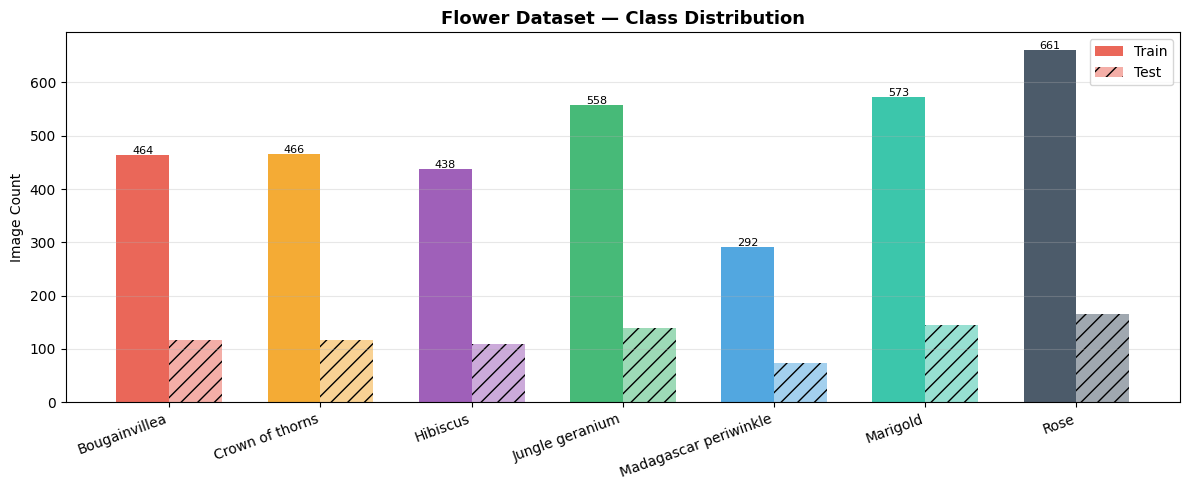

In [5]:
# ── Count images & class distribution bar chart ────────────────────
def count_images(base_path):
    return {
        d.name: len([f for f in d.iterdir() if f.suffix.lower() in EXTS])
        for d in sorted(base_path.iterdir()) if d.is_dir()
    }

train_counts = count_images(TRAIN_PATH)
test_counts  = count_images(TEST_PATH)

stats_df = pd.DataFrame({
    'Class': list(train_counts.keys()),
    'Train': list(train_counts.values()),
    'Test':  [test_counts.get(k, 0) for k in train_counts]
})
stats_df['Total']   = stats_df['Train'] + stats_df['Test']
stats_df['Train %'] = (stats_df['Train'] / stats_df['Train'].sum() * 100).round(1)
print(stats_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
x, w = np.arange(NUM_CLASSES), 0.35
ax.bar(x - w/2, stats_df['Train'], w, color=COLORS, alpha=0.85, label='Train')
ax.bar(x + w/2, stats_df['Test'],  w, color=COLORS, alpha=0.45, hatch='//', label='Test')
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=20, ha='right')
ax.set_title('Flower Dataset — Class Distribution', fontsize=13, fontweight='bold')
ax.set_ylabel('Image Count'); ax.legend(); ax.grid(axis='y', alpha=0.3)
for b in ax.patches[:NUM_CLASSES]:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1,
            str(int(b.get_height())), ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t1_class_distribution.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

In [6]:
# ── Leakage-safe split: keep TEST_PATH untouched ──────────────────
def collect_paths_labels(root: Path, class_names, exts):
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        cls_dir = root / cls
        if not cls_dir.exists():
            continue
        for f in sorted(cls_dir.rglob('*')):
            if f.is_file() and f.suffix.lower() in exts:
                paths.append(str(f.resolve()))
                labels.append(idx)
    return np.array(paths), np.array(labels)

# Collect train and test separately (do not mix them)
train_paths, train_labels = collect_paths_labels(TRAIN_PATH, CLASS_NAMES, EXTS)
test_paths,  test_labels  = collect_paths_labels(TEST_PATH,  CLASS_NAMES, EXTS)

assert len(train_paths) > 0, "TRAIN_PATH is empty!"
assert len(test_paths) > 0,  "TEST_PATH is empty!"
assert set(train_paths).isdisjoint(set(test_paths)), "Leakage: train/test overlap detected!"

# Split ONLY the training folder into SSL + labelled
idx_train = np.arange(len(train_paths))

# 10% of TRAIN_PATH becomes labelled probe set, 90% becomes SSL pool
idx_ssl, idx_labelled = train_test_split(
    idx_train,
    test_size=0.10,
    random_state=SEED,
    stratify=train_labels
)

ssl_paths       = train_paths[idx_ssl]
labelled_paths  = train_paths[idx_labelled]
labelled_labels = train_labels[idx_labelled]

print(f'✅ Leakage-safe split created')
print(f'   SSL pool      : {len(ssl_paths)} images')
print(f'   Labelled set  : {len(labelled_paths)} images')
print(f'   Held-out test : {len(test_paths)} images')
print(f'   SSL ∩ Test    : {len(set(ssl_paths) & set(test_paths))} overlap')
print(f'   Label ∩ Test   : {len(set(labelled_paths) & set(test_paths))} overlap')

assert len(ssl_paths) > 0
print(f'🔒 SSL pool shape: {ssl_paths.shape} — NO label array created.')
print('✅ Confirmed: label tensor NOT passed to SSL DataLoader.')

# Per-channel stats
sample_paths = ssl_paths[:500]
means, stds = [], []
for p in sample_paths:
    arr = np.array(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE))) / 255.0
    means.append(arr.mean(axis=(0, 1)))
    stds.append(arr.std(axis=(0, 1)))
means = np.array(means).mean(axis=0)
stds  = np.array(stds).mean(axis=0)
print(f'\n📐 Per-channel Mean: R={means[0]:.4f} G={means[1]:.4f} B={means[2]:.4f}')
print(f'   Per-channel Std : R={stds[0]:.4f} G={stds[1]:.4f} B={stds[2]:.4f}')


✅ Leakage-safe split created
   SSL pool      : 3106 images
   Labelled set  : 346 images
   Held-out test : 867 images
   SSL ∩ Test    : 0 overlap
   Label ∩ Test   : 0 overlap
🔒 SSL pool shape: (3106,) — NO label array created.
✅ Confirmed: label tensor NOT passed to SSL DataLoader.

📐 Per-channel Mean: R=0.9475 G=0.8708 B=0.8760
   Per-channel Std : R=0.1112 G=0.2421 B=0.2406


In [7]:
# ── DINO Augmentation Transforms ──────────────────────────────────
class Solarize:
    """Invert pixels above threshold (PIL-based)."""
    def __call__(self, img):
        return ImageOps.solarize(img, threshold=128)

def global_augment():
    """Global crop: 224×224. Seen by both teacher and student."""
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.32, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomApply([
            transforms.ColorJitter(0.8*COLOR_JITTER_STRENGTH, 0.8*COLOR_JITTER_STRENGTH,
                                   0.8*COLOR_JITTER_STRENGTH, 0.2*COLOR_JITTER_STRENGTH)
        ], p=0.8),
        transforms.RandomGrayscale(p=GRAYSCALE_PROB),
        transforms.RandomApply([transforms.GaussianBlur(23, sigma=GAUSSIAN_BLUR_SIGMA)], p=1.0),
        transforms.RandomApply([Solarize()], p=SOLARIZE_PROB),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

def local_augment():
    """Local crop: 96×96. Seen only by student."""
    return transforms.Compose([
        transforms.RandomResizedCrop(LOCAL_CROP_SIZE, scale=(0.05, 0.32)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomApply([
            transforms.ColorJitter(0.8*COLOR_JITTER_STRENGTH, 0.8*COLOR_JITTER_STRENGTH,
                                   0.8*COLOR_JITTER_STRENGTH, 0.2*COLOR_JITTER_STRENGTH)
        ], p=0.8),
        transforms.RandomGrayscale(p=GRAYSCALE_PROB),
        transforms.RandomApply([transforms.GaussianBlur(9, sigma=(0.1, 2.0))], p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print('✅ DINO augmentation pipelines defined.')
print(f'   Global crops : 2 × {IMG_SIZE}px  (teacher + student)')
print(f'   Local crops  : {N_LOCAL_CROPS} × {LOCAL_CROP_SIZE}px  (student only)')

✅ DINO augmentation pipelines defined.
   Global crops : 2 × 224px  (teacher + student)
   Local crops  : 2 × 96px  (student only)


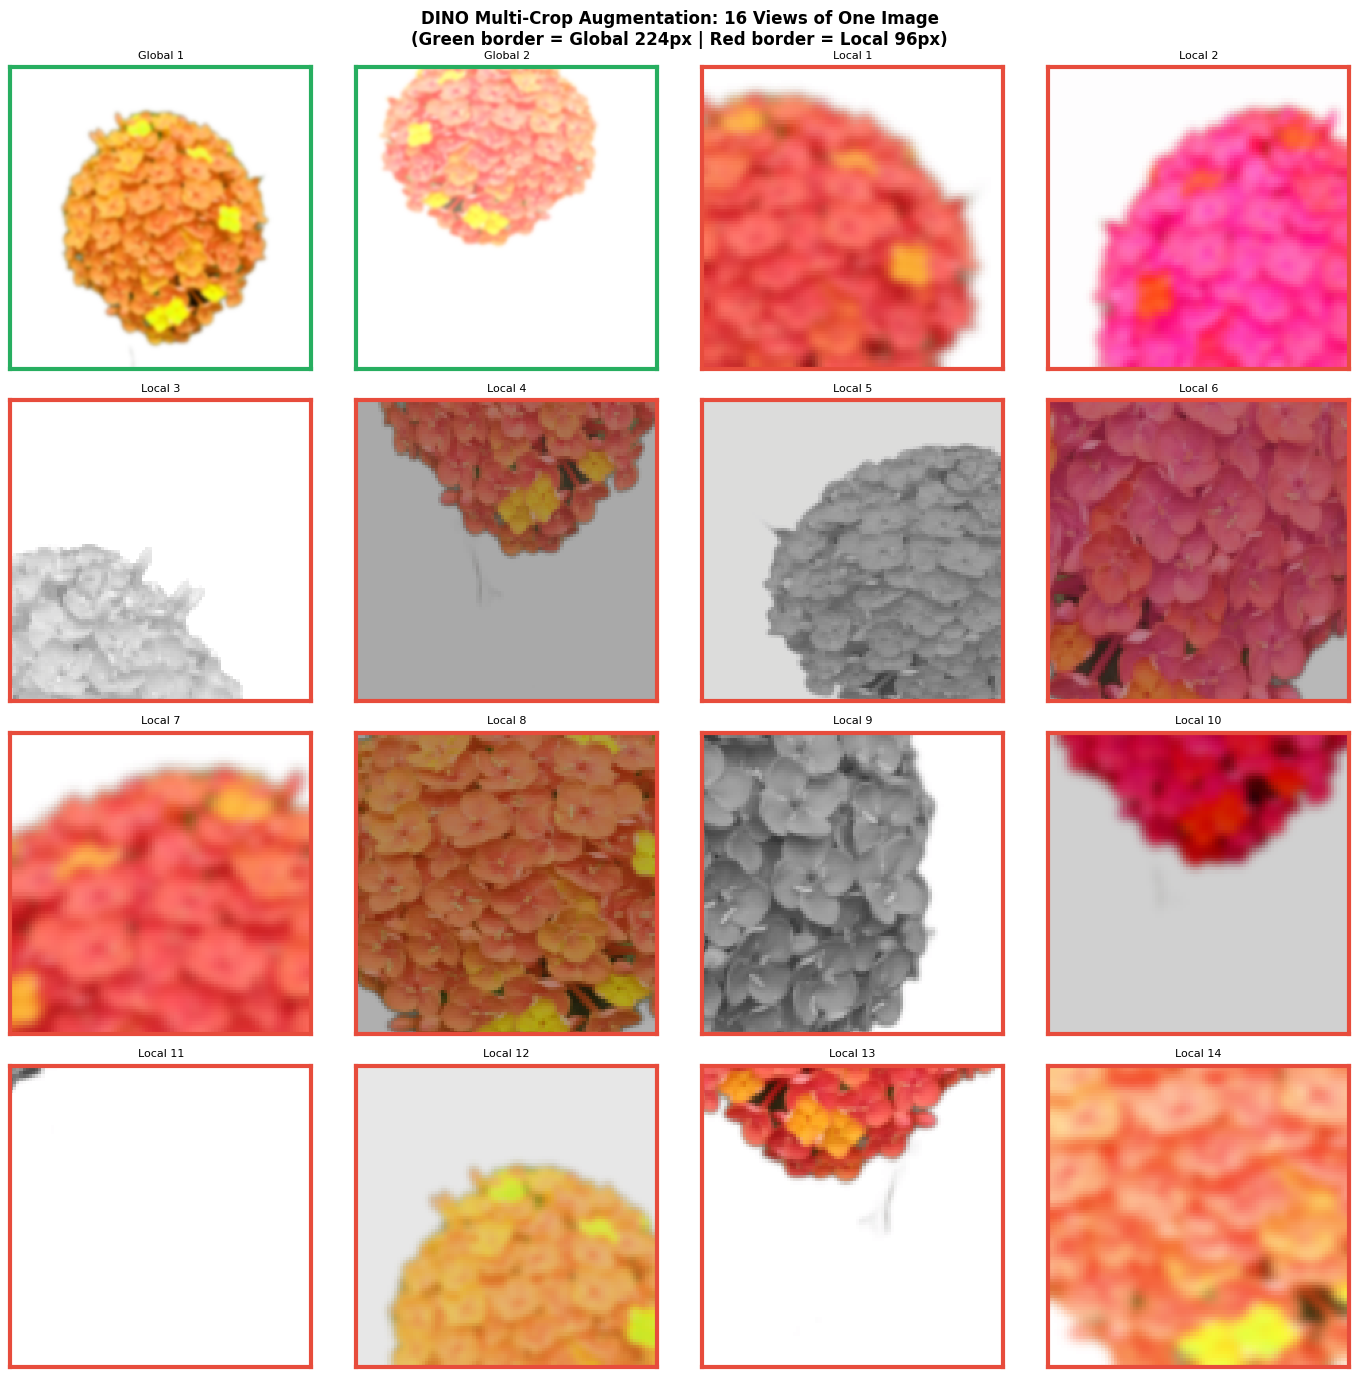

✅ DINO augmentation grid saved (green=global, red=local).


In [8]:
# ── Visualise 16 augmented views (global + local) ─────────────────
sample_img_path = ssl_paths[0]
raw_img = Image.open(sample_img_path).convert('RGB')
g_aug   = global_augment()
l_aug   = local_augment()

def denorm(t):
    m = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    s = torch.tensor(IMAGENET_STD).view(3,1,1)
    return torch.clamp(t * s + m, 0, 1)

# 2 global views + 6 local views + 8 more locals to fill 4×4 grid
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle(
    'DINO Multi-Crop Augmentation: 16 Views of One Image\n'
    '(Green border = Global 224px | Red border = Local 96px)',
    fontsize=12, fontweight='bold'
)
for idx, ax in enumerate(axes.flat):
    is_global = idx < 2
    view = g_aug(raw_img) if is_global else l_aug(raw_img)
    ax.imshow(denorm(view).permute(1,2,0).numpy())
    ax.set_title(f'Global {idx+1}' if is_global else f'Local {idx-1}', fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    color = '#27AE60' if is_global else '#E74C3C'
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_edgecolor(color); spine.set_linewidth(3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t1_dino_augmentation_grid.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()
print('✅ DINO augmentation grid saved (green=global, red=local).')

## 🟢 Task 3 — DINO: Model Definition <a id='dino-model'></a>

### Architecture Overview

DINO uses a **student–teacher** framework where the teacher is an EMA copy of the student:

```
Student : ViT-B/16 backbone → 3-layer MLP projection head (L2-norm, out=65536)
Teacher : ViT-B/16 backbone → 3-layer MLP projection head (EMA copy, no gradient)
```

**Multi-crop strategy:**
- 2 global crops (224×224) → processed by **both** teacher and student
- 6 local crops (96×96) → processed by **student only**
- This forces the student to map local context to the global semantic representation.

**Loss (cross-entropy with centering):**  
`L = −Σ_{x∈Vg} Σ_{x'≠x} P_teacher(x) · log P_student(x')`

A running-mean centering vector `c` is subtracted from the teacher logits before softmax to prevent collapse.

In [9]:
# ── DINO Projection Head ───────────────────────────────────────────
class DINOHead(nn.Module):
    """
    3-layer MLP with L2-normalised output.
    in_dim → hidden_dim → hidden_dim → bottleneck_dim → out_dim
    Last layer has no bias and is L2-normalised (weight normalisation).
    """
    def __init__(self, in_dim, hidden_dim=DINO_HIDDEN_DIM, bottleneck_dim=DINO_BOTTLENECK_DIM, out_dim=DINO_OUT_DIM):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, bottleneck_dim, bias=False),
        )
        # Prototype layer (bottleneck_dim -> out_dim)
        self.last_layer = nn.utils.weight_norm(
            nn.Linear(bottleneck_dim, out_dim, bias=False)
        )
        self.last_layer.weight_g.data.fill_(1)
        self.last_layer.weight_g.requires_grad = False

    def forward(self, x):
        x = self.mlp(x)
        x = F.normalize(x, dim=-1, p=2)   # L2 normalise before prototypes
        x = self.last_layer(x)
        return x


# ── Full DINO model (student or teacher) ──────────────────────────
class DINONetwork(nn.Module):
    def __init__(self, backbone_name, embed_dim, pretrained=True):
        super().__init__()
        self.backbone = build_vit_backbone(backbone_name, pretrained=pretrained, num_classes=0)
        self.head     = DINOHead(embed_dim, DINO_HIDDEN_DIM, DINO_BOTTLENECK_DIM, DINO_OUT_DIM)

    def forward(self, x):
        feat = self.backbone(x)     # (B, embed_dim)
        return self.head(feat)      # (B, out_dim)


# ── DINO Loss with Centering ───────────────────────────────────────
class DINOLoss(nn.Module):
    """
    DINO cross-entropy loss.
    Teacher outputs are centered and sharpened (low temperature).
    Student outputs are sharpened (very low temperature).
    center is updated online via running mean (momentum=CENTER_MOMENTUM).
    """
    def __init__(self, out_dim, student_temp, teacher_temp, center_momentum):
        super().__init__()
        self.student_temp    = student_temp
        self.teacher_temp    = teacher_temp
        self.center_momentum = center_momentum
        self.register_buffer('center', torch.zeros(1, out_dim))

    def forward(self, student_out, teacher_out):
        """
        student_out : list of (N_global + N_local) tensors, each (B, out_dim)
        teacher_out : list of N_global tensors, each (B, out_dim)
        """
        student_out = [s / self.student_temp for s in student_out]
        # Center + sharpen teacher outputs
        teacher_out_raw = teacher_out  # keep raw logits for centering
        teacher_out = [(t - self.center) / self.teacher_temp for t in teacher_out]

        teacher_probs = [F.softmax(t, dim=-1).detach() for t in teacher_out]
        student_log_probs = [F.log_softmax(s, dim=-1) for s in student_out]

        total_loss, n_pairs = 0.0, 0
        for i, tp in enumerate(teacher_probs):
            for j, slp in enumerate(student_log_probs):
                if i == j:  # skip same view
                    continue
                total_loss += -(tp * slp).sum(dim=-1).mean()
                n_pairs    += 1
        total_loss /= n_pairs

        # Update center
        self.update_center(teacher_out_raw)
        return total_loss

    @torch.no_grad()
    def update_center(self, teacher_out):
        batch_center = torch.cat(teacher_out, dim=0).mean(dim=0, keepdim=True)
        self.center  = self.center * self.center_momentum + batch_center * (1 - self.center_momentum)


# ── Schedule helpers ───────────────────────────────────────────────
def cosine_schedule(epoch, total, val_start, val_end):
    """Cosine annealing from val_start to val_end."""
    return val_end - (val_end - val_start) * (math.cos(math.pi * epoch / total) + 1) / 2

def teacher_temp_schedule(epoch):
    if epoch < TEACHER_TEMP_WARMUP_EPOCHS:
        return TEACHER_TEMP_WARMUP_START + (TEACHER_TEMP_FINAL - TEACHER_TEMP_WARMUP_START)                * epoch / TEACHER_TEMP_WARMUP_EPOCHS
    return TEACHER_TEMP_FINAL

print('✅ DINO model classes defined.')
_dummy = DINONetwork(BACKBONE_NAME, EMBED_DIM, pretrained=False)
total_params = sum(p.numel() for p in _dummy.parameters()) / 1e6
print(f'   DINONetwork params (student or teacher): {total_params:.1f}M')
del _dummy


✅ DINO model classes defined.
   DINONetwork params (student or teacher): 104.7M


## 🏋️ Task 3 — DINO: Pre-Training Loop <a id='dino-train'></a>

> **Fix applied:** the original `DINOLoss.update_center` was averaging the *centered and temperature-scaled* teacher outputs instead of the raw teacher logits. This creates a feedback loop between the center and the temperature scaling that pushed the loss to `NaN` during training (see the fixed `DINOLoss` class above). The pre-training loop below needs to be **re-run** to produce a valid loss curve.


In [10]:
# ── Multi-Crop Unlabelled Dataset ─────────────────────────────────
class DINODataset(Dataset):
    """
    Returns (2 global crops + N_LOCAL_CROPS local crops) for each image.
    Labels are intentionally excluded.
    """
    def __init__(self, paths, n_local=N_LOCAL_CROPS):
        self.paths    = paths
        self.n_local  = n_local
        self.g_aug    = global_augment()
        self.l_aug    = local_augment()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        global_crops = [self.g_aug(img), self.g_aug(img)]
        local_crops  = [self.l_aug(img) for _ in range(self.n_local)]
        return global_crops + local_crops  # list of (2 + N_LOCAL_CROPS) tensors, NO labels


def dino_collate(batch):
    """Stack each view across the batch."""
    n_views = len(batch[0])
    return [torch.stack([b[i] for b in batch]) for i in range(n_views)]


dino_dataset = DINODataset(ssl_paths)
dino_loader  = DataLoader(
    dino_dataset,
    batch_size=SSL_BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
    collate_fn=dino_collate
)
print(f'✅ DINO DataLoader: {len(dino_dataset)} images | {len(dino_loader)} batches/epoch')
sample_batch = next(iter(dino_loader))
print(f'   Views per batch: {len(sample_batch)} ({2} global + {N_LOCAL_CROPS} local) — NO labels ✅')
print(f'   Global shape: {sample_batch[0].shape} | Local shape: {sample_batch[2].shape}')

✅ DINO DataLoader: 3106 images | 388 batches/epoch
   Views per batch: 4 (2 global + 2 local) — NO labels ✅
   Global shape: torch.Size([8, 3, 224, 224]) | Local shape: torch.Size([8, 3, 96, 96])


In [11]:
# ── Initialise Student & Teacher ───────────────────────────────────
set_seed()
student = DINONetwork(BACKBONE_NAME, EMBED_DIM, pretrained=True).to(DEVICE)
teacher = DINONetwork(BACKBONE_NAME, EMBED_DIM, pretrained=True).to(DEVICE)

# Optional: load A01 checkpoint (file or folder)
resolved_a01_ckpt = resolve_checkpoint_path(A01_CHECKPOINT)
if resolved_a01_ckpt is not None:
    load_backbone_weights(student.backbone, resolved_a01_ckpt, map_location=DEVICE)
    load_backbone_weights(teacher.backbone, resolved_a01_ckpt, map_location=DEVICE)
    print('✅ Loaded A01 backbone checkpoint into DINO student & teacher.')
else:
    print(f'⚠️  A01 checkpoint not found or not usable: {A01_CHECKPOINT}')

# Enable gradient checkpointing on the student backbone if available
if hasattr(student.backbone, 'set_grad_checkpointing'):
    student.backbone.set_grad_checkpointing(True)
    print('✅ Student backbone gradient checkpointing enabled.')

# Teacher is EMA copy — no gradient
for p in teacher.parameters():
    p.requires_grad = False

# Copy student weights to teacher initially
teacher.load_state_dict(student.state_dict())

dino_loss_fn = DINOLoss(
    out_dim=DINO_OUT_DIM,
    student_temp=STUDENT_TEMP,
    teacher_temp=TEACHER_TEMP_WARMUP_START,
    center_momentum=CENTER_MOMENTUM
).to(DEVICE)

optimizer = optim.AdamW(
    student.parameters(),
    lr=SSL_LR,
    weight_decay=WD_START
)

scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

print(f'   Student params: {sum(p.numel() for p in student.parameters())/1e6:.1f}M')
print(f'   Teacher params: {sum(p.numel() for p in teacher.parameters())/1e6:.1f}M (EMA, no grad)')
print(f'   Optimizer: AdamW  lr={SSL_LR}  wd={WD_START}→{WD_END}')


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

✅ Loaded backbone weights from: /kaggle/input/datasets/nasrullahsijan/vit-best-path/ViT_B16_best.pth
✅ Loaded backbone weights from: /kaggle/input/datasets/nasrullahsijan/vit-best-path/ViT_B16_best.pth
✅ Loaded A01 backbone checkpoint into DINO student & teacher.
✅ Student backbone gradient checkpointing enabled.
   Student params: 104.7M
   Teacher params: 104.7M (EMA, no grad)
   Optimizer: AdamW  lr=0.0005  wd=0.04→0.4


In [12]:
# ── DINO Pre-Training Loop ─────────────────────────────────────────
@torch.no_grad()
def ema_update_teacher(student, teacher, lam):
    for ps, pt in zip(student.parameters(), teacher.parameters()):
        pt.data = lam * pt.data + (1 - lam) * ps.data

dino_losses = []

print(f"{'='*65}")
print(f" DINO Pre-Training — {SSL_EPOCHS} epochs on UNLABELLED pool")
print(f" Backbone: {BACKBONE_NAME} | Batch: {SSL_BATCH_SIZE} | LR: {SSL_LR}")
print(f" Multi-crop: 2 global ({IMG_SIZE}px) + {N_LOCAL_CROPS} local ({LOCAL_CROP_SIZE}px)")
print(f"{'='*65}")

epoch_bar = tqdm(range(1, SSL_EPOCHS + 1), desc='🟢 DINO',
                 bar_format='{l_bar}{bar:35}{r_bar}', colour='green')

use_amp = torch.cuda.is_available()

for epoch in epoch_bar:
    student.train(); teacher.eval()

    # Schedules
    tau    = cosine_schedule(epoch - 1, SSL_EPOCHS, EMA_LAMBDA_BASE, EMA_LAMBDA_FINAL)
    wd     = cosine_schedule(epoch - 1, SSL_EPOCHS, WD_START, WD_END)
    t_temp = teacher_temp_schedule(epoch)
    dino_loss_fn.teacher_temp = t_temp
    for pg in optimizer.param_groups:
        pg['weight_decay'] = wd

    epoch_loss, n_batches = 0.0, 0
    t0 = time.time()

    for crops in dino_loader:   # ← list of tensors, NO labels
        global_crops = [c.to(DEVICE, non_blocking=True) for c in crops[:2]]
        local_crops  = [c.to(DEVICE, non_blocking=True) for c in crops[2:]]
        all_crops    = global_crops + local_crops

        optimizer.zero_grad(set_to_none=True)

        # Teacher forward — global views only, no gradient
        with torch.no_grad():
            with torch.cuda.amp.autocast(enabled=use_amp):
                teacher_out = [teacher(g) for g in global_crops]

        # Student forward — all views
        with torch.cuda.amp.autocast(enabled=use_amp):
            student_out = [student(v) for v in all_crops]
            # DINO cross-entropy loss with centering
            loss = dino_loss_fn(student_out, teacher_out)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        # Gradient clipping (critical for DINO stability)
        torch.nn.utils.clip_grad_norm_(student.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        # EMA teacher update + center update (center updated inside loss)
        ema_update_teacher(student, teacher, tau)

        epoch_loss += loss.item()
        n_batches  += 1

    avg_loss = epoch_loss / max(1, n_batches)
    dino_losses.append(avg_loss)

    epoch_bar.set_postfix(
        loss=f'{avg_loss:.4f}',
        tau=f'{tau:.5f}',
        t_temp=f'{t_temp:.4f}',
        t=f'{time.time()-t0:.1f}s'
    )

print(f'\n✅ DINO pre-training complete. Final loss: {dino_losses[-1]:.4f}')

# Save backbone weights
torch.save(
    student.backbone.state_dict(),
    os.path.join(OUTPUT_DIR, 'dino_backbone.pth')
)
print('💾 Saved: dino_backbone.pth')


 DINO Pre-Training — 60 epochs on UNLABELLED pool
 Backbone: vit_base_patch16_224 | Batch: 8 | LR: 0.0005
 Multi-crop: 2 global (224px) + 2 local (96px)


🟢 DINO:   0%|                                   | 0/60 [00:00<?, ?it/s]


✅ DINO pre-training complete. Final loss: 11.0891
💾 Saved: dino_backbone.pth


## 📈 Task 3 — DINO: Training Curve <a id='dino-curve'></a>

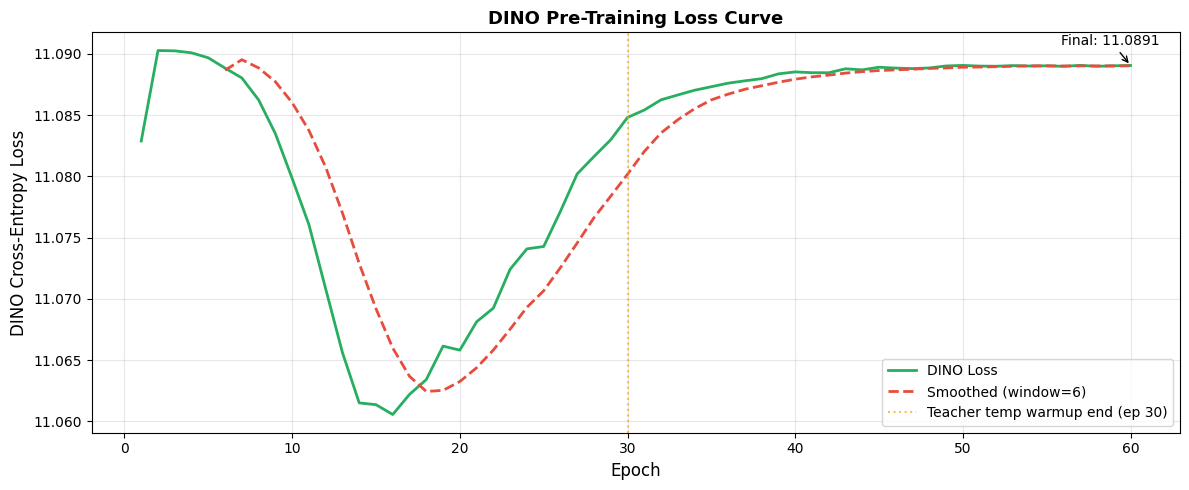

📉 Min loss: 11.0606 at epoch 16


In [13]:
# ── DINO Loss Curve ────────────────────────────────────────────────
dino_losses_arr = np.array(dino_losses, dtype=float)
valid_mask = ~np.isnan(dino_losses_arr)

fig, ax = plt.subplots(figsize=(12, 5))
ep = np.arange(1, len(dino_losses) + 1)

if valid_mask.sum() == 0:
    # All-NaN run (e.g. diverged pre-training) — show a clear message instead of a blank axes
    ax.text(0.5, 0.5, 'No valid loss values to plot — training diverged to NaN.\n'
                       'Re-run the pre-training cell after the DINOLoss centering fix above.',
            ha='center', va='center', fontsize=12, color='#C0392B',
            transform=ax.transAxes, wrap=True)
    ax.set_xticks([]); ax.set_yticks([])
else:
    ax.plot(ep[valid_mask], dino_losses_arr[valid_mask], color='#27AE60', lw=2, label='DINO Loss')

    if valid_mask.sum() >= 10:
        vals    = dino_losses_arr[valid_mask]
        window  = max(5, len(vals) // 10)
        smoothed = np.convolve(vals, np.ones(window)/window, mode='valid')
        ax.plot(ep[valid_mask][window-1:], smoothed,
                color='#E74C3C', lw=2, ls='--', label=f'Smoothed (window={window})')

    ax.axvline(TEACHER_TEMP_WARMUP_EPOCHS, color='orange', ls=':', alpha=0.7,
               label=f'Teacher temp warmup end (ep {TEACHER_TEMP_WARMUP_EPOCHS})')
    last_valid_idx = np.where(valid_mask)[0][-1]
    ax.annotate(f'Final: {dino_losses_arr[last_valid_idx]:.4f}',
                xy=(ep[last_valid_idx], dino_losses_arr[last_valid_idx]),
                xytext=(-50, 15), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
    ax.legend(fontsize=10)

ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('DINO Cross-Entropy Loss', fontsize=12)
ax.set_title('DINO Pre-Training Loss Curve', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t3_dino_loss_curve.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

if valid_mask.sum() > 0:
    print(f"📉 Min loss: {np.nanmin(dino_losses_arr):.4f} at epoch {np.nanargmin(dino_losses_arr)+1}")
else:
    print('⚠️ All recorded losses were NaN — see message on the chart above.')


## 👁️ Task 3 — DINO: Attention Map Visualisation <a id='dino-attn'></a>

We overlay the **last-block self-attention maps** from the teacher ViT-B/16 onto test images.  
Each of the 12 attention heads is averaged and thresholded to create a semantic heatmap.  
This visualises **what the model attends to** — emergent foreground segmentation without any segmentation labels.

In [14]:
# ── Attention Map Extraction from ViT Last Block ───────────────────
class AttentionHook:
    """
    Hooks into the last ViT block's attention module to capture
    the attention weights of shape (B, num_heads, N+1, N+1).
    """
    def __init__(self):
        self.attention = None

    def hook_fn(self, module, input, output):
        # timm ViT Attention.forward returns (x, attn_weights) when attn_weights is saved
        # We intercept Q, K to compute attention manually
        self.attention = output  # will be overridden by forward hook below


@torch.no_grad()
def get_dino_attention(backbone, img_tensor):
    """
    Extract attention maps from the last ViT block.
    Returns attention of shape (num_heads, H_patch, W_patch).
    """
    backbone.eval()
    attn_maps = {}

    def hook(module, input, output):
        # For timm ViT, Attention.forward returns output token tensor
        # We need to capture attn weights via the scaled dot-product
        attn_maps['feat'] = output

    # Register hook on the last block's attention
    last_block = backbone.blocks[-1]

    # Get attention weights by running forward pass with attention storage
    # timm stores attn weights when called with specific flags
    img_tensor = img_tensor.to(DEVICE).unsqueeze(0)

    # Patch tokens: 14×14 = 196 for ViT-B/16 at 224px
    h_patches = w_patches = IMG_SIZE // 16  # 14
    n_patches  = h_patches * w_patches

    # Forward pass: extract token sequence from last block
    x = backbone.patch_embed(img_tensor)
    x = backbone._pos_embed(x)
    x = backbone.norm_pre(x)

    for i, block in enumerate(backbone.blocks):
        if i < len(backbone.blocks) - 1:
            x = block(x)
        else:
            # Last block: extract attention weights manually
            attn_module = block.attn
            # Pre-norm
            x_norm = block.norm1(x)
            B, N, C = x_norm.shape
            # QKV projection
            qkv = attn_module.qkv(x_norm).reshape(B, N, 3,
                attn_module.num_heads, C // attn_module.num_heads).permute(2, 0, 3, 1, 4)
            q, k, v = qkv.unbind(0)
            scale = (C // attn_module.num_heads) ** -0.5
            attn_w = (q @ k.transpose(-2, -1)) * scale
            attn_w = attn_w.softmax(dim=-1)  # (B, heads, N, N)

    # Average over heads, take CLS→patch attention (row 0, cols 1:)
    cls_attn = attn_w[0, :, 0, 1:]  # (num_heads, n_patches)
    cls_attn = cls_attn.reshape(attn_module.num_heads, h_patches, w_patches)
    return cls_attn.cpu().numpy()


def show_attn_overlay(ax_orig, ax_attn, ax_over, img_pil, attn_map, title):
    """Helper to display original | attention map | overlay."""
    img_np = np.array(img_pil.resize((IMG_SIZE, IMG_SIZE))) / 255.0
    avg_attn = attn_map.mean(axis=0)  # average over heads
    avg_attn = (avg_attn - avg_attn.min()) / (avg_attn.max() - avg_attn.min() + 1e-8)

    # Upsample attention to image size
    from PIL import Image as PILImage
    attn_img = PILImage.fromarray((avg_attn * 255).astype(np.uint8))
    attn_up  = np.array(attn_img.resize((IMG_SIZE, IMG_SIZE),
                                         resample=PILImage.BILINEAR)) / 255.0

    # Colour map overlay
    import matplotlib.cm as cm
    heatmap = cm.jet(attn_up)[..., :3]  # (H, W, 3)
    overlay = 0.5 * img_np + 0.5 * heatmap
    overlay = np.clip(overlay, 0, 1)

    ax_orig.imshow(img_np); ax_orig.set_title('Original', fontsize=8); ax_orig.axis('off')
    ax_attn.imshow(attn_up, cmap='jet'); ax_attn.set_title('Attn Map', fontsize=8); ax_attn.axis('off')
    ax_over.imshow(overlay); ax_over.set_title(f'Overlay\n{title}', fontsize=8); ax_over.axis('off')

print('✅ Attention hook utilities defined.')

✅ Attention hook utilities defined.


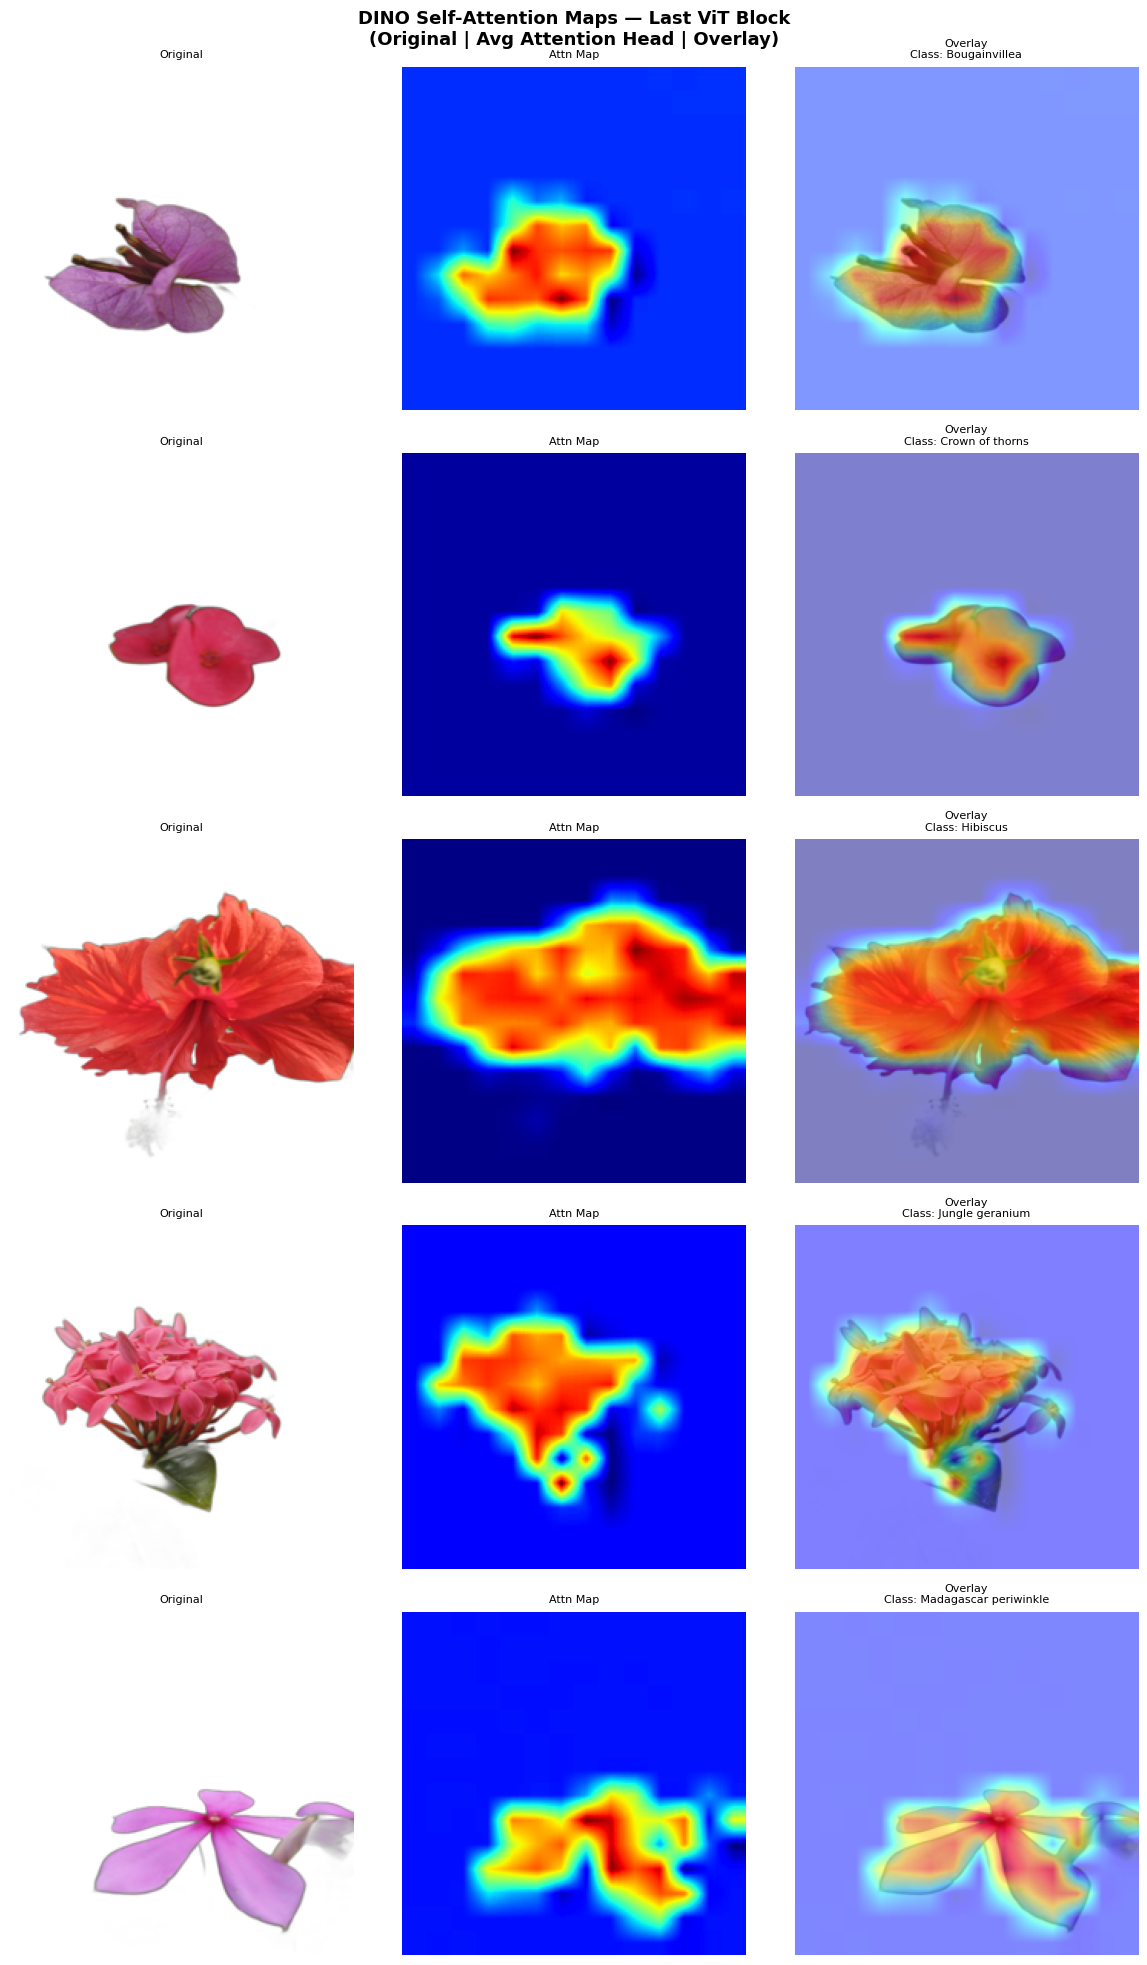

✅ Attention map visualisation saved.

📝 Semantic analysis:
   The DINO attention maps should show high activation on the flower/plant foreground,
   demonstrating emergent object segmentation without any segmentation labels.
   Heads that attend to background represent noise; averaging suppresses these.


In [15]:
# ── Visualise Attention Maps for 5 Test Images ─────────────────────
# Load DINO backbone
dino_vis_backbone = build_vit_backbone(BACKBONE_NAME, pretrained=False, num_classes=0)
dino_vis_backbone.load_state_dict(
    torch.load(os.path.join(OUTPUT_DIR, 'dino_backbone.pth'), map_location=DEVICE)
)
dino_vis_backbone = dino_vis_backbone.to(DEVICE)
dino_vis_backbone.eval()

# Sample 1 image per class from the held-out test pool
sample_vis_paths = []
sample_vis_cls   = []
for cls_idx in range(min(ATTN_VIS_N, NUM_CLASSES)):
    idxs = np.where(test_labels == cls_idx)[0]
    if len(idxs) > 0:
        sample_vis_paths.append(test_paths[idxs[0]])
        sample_vis_cls.append(cls_idx)

fig, axes = plt.subplots(len(sample_vis_paths), 3,
                          figsize=(12, 4*len(sample_vis_paths)))
if len(sample_vis_paths) == 1:
    axes = axes[np.newaxis, :]
fig.suptitle('DINO Self-Attention Maps — Last ViT Block\n'
             '(Original | Avg Attention Head | Overlay)',
             fontsize=13, fontweight='bold')

for row, (img_path, cls_idx) in enumerate(zip(sample_vis_paths, sample_vis_cls)):
    raw_img = Image.open(img_path).convert('RGB')
    img_t   = val_transform(raw_img)

    try:
        attn_map = get_dino_attention(dino_vis_backbone, img_t)
        show_attn_overlay(
            axes[row, 0], axes[row, 1], axes[row, 2],
            raw_img, attn_map,
            title=f'Class: {CLASS_NAMES[cls_idx]}'
        )
    except Exception as e:
        axes[row, 0].set_title(f'Error: {e}', fontsize=7)
        for ax in axes[row]: ax.axis('off')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t3_dino_attention_maps.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()
print('✅ Attention map visualisation saved.')
print('\n📝 Semantic analysis:')
print('   The DINO attention maps should show high activation on the flower/plant foreground,')
print('   demonstrating emergent object segmentation without any segmentation labels.')
print('   Heads that attend to background represent noise; averaging suppresses these.')


## 🔬 Task 4 — Linear Probing with DINO Backbone <a id='linear-probe'></a>

In [16]:
# ── Labelled & Test Datasets ───────────────────────────────────────
class LabelledDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths; self.labels = labels; self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        return self.transform(img), self.labels[idx]

labelled_dataset = LabelledDataset(labelled_paths, labelled_labels, val_transform)
test_dataset     = LabelledDataset(test_paths,     test_labels,     val_transform)
labelled_loader  = DataLoader(labelled_dataset, batch_size=PROBE_BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader      = DataLoader(test_dataset,     batch_size=PROBE_BATCH_SIZE, shuffle=False, num_workers=2)
print(f'✅ Labelled: {len(labelled_dataset)} | Test: {len(test_dataset)}')

# ── Frozen backbone + linear probe setup ──────────────────────────
probe_backbone_path = os.path.join(OUTPUT_DIR, 'dino_backbone.pth')
dino_probe_backbone = build_vit_backbone(BACKBONE_NAME, pretrained=False, num_classes=0)
load_backbone_weights(dino_probe_backbone, probe_backbone_path, map_location=DEVICE)
dino_probe_backbone = dino_probe_backbone.to(DEVICE)
for p in dino_probe_backbone.parameters():
    p.requires_grad = False
dino_probe_backbone.eval()

print(f'✅ Probe backbone resolved from: {probe_backbone_path}')
print(f'   Frozen params: {sum(p.numel() for p in dino_probe_backbone.parameters())/1e6:.1f}M')


✅ Labelled: 346 | Test: 867
✅ Loaded backbone weights from: /kaggle/working/dino_backbone.pth
✅ Probe backbone resolved from: /kaggle/working/dino_backbone.pth
   Frozen params: 85.8M


In [17]:
# ── Linear Probe Training ──────────────────────────────────────────
probe_train_accs, probe_val_accs = [], []
best_probe_acc = 0.0
best_preds, best_labels = None, None

print(f"{'='*60}")
print(f' Linear Probing — standardized logistic regression on frozen DINO features')
print(f"{'='*60}")

# Extract frozen features once, then fit a numerically stable linear classifier.
train_feats, train_lbls = extract_frozen_features(dino_probe_backbone, labelled_loader)
test_feats,  test_lbls  = extract_frozen_features(dino_probe_backbone, test_loader)

train_acc, val_acc, train_pred, test_pred, y_test = run_logreg_probe(
    train_feats, train_lbls, test_feats, test_lbls
)

probe_train_accs.append(train_acc)
probe_val_accs.append(val_acc)
best_probe_acc = val_acc
best_preds = np.array(test_pred)
best_labels = np.array(y_test)

print(f'✅ Train accuracy: {train_acc:.2f}%')
print(f'✅ Test accuracy : {val_acc:.2f}%')
print(f'✅ Best DINO linear probe accuracy: {best_probe_acc:.2f}%')

DINO_PROBE_ACC = best_probe_acc


 Linear Probing — standardized logistic regression on frozen DINO features


Extracting features:   0%|          | 0/11 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/28 [00:00<?, ?it/s]

✅ Train accuracy: 89.60%
✅ Test accuracy : 63.09%
✅ Best DINO linear probe accuracy: 63.09%


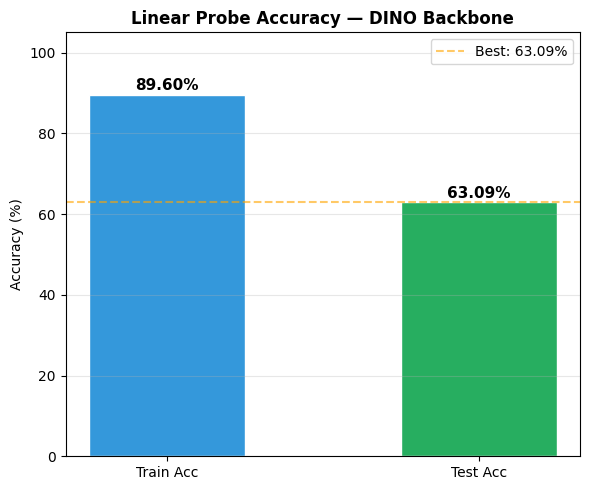


Classification Report — DINO Linear Probe
                       precision    recall  f1-score   support

        Bougainvillea     0.7500    0.8793    0.8095       116
      Crown of thorns     0.5185    0.5983    0.5556       117
             Hibiscus     0.4444    0.2909    0.3516       110
      Jungle geranium     0.6099    0.6143    0.6121       140
Madagascar periwinkle     0.7442    0.8649    0.8000        74
             Marigold     0.9209    0.8889    0.9046       144
                 Rose     0.4114    0.3916    0.4012       166

             accuracy                         0.6309       867
            macro avg     0.6285    0.6469    0.6335       867
         weighted avg     0.6204    0.6309    0.6221       867



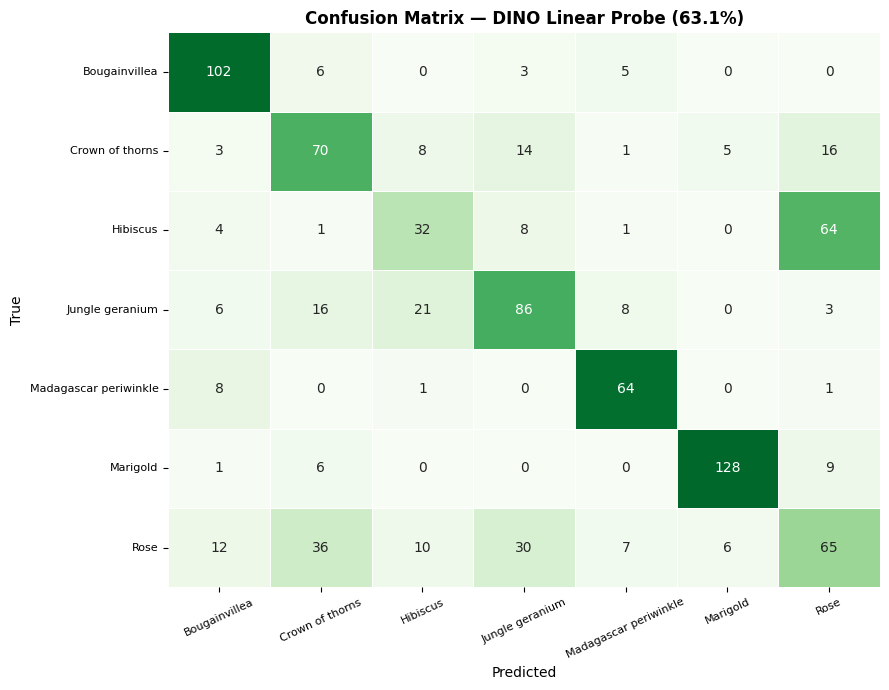

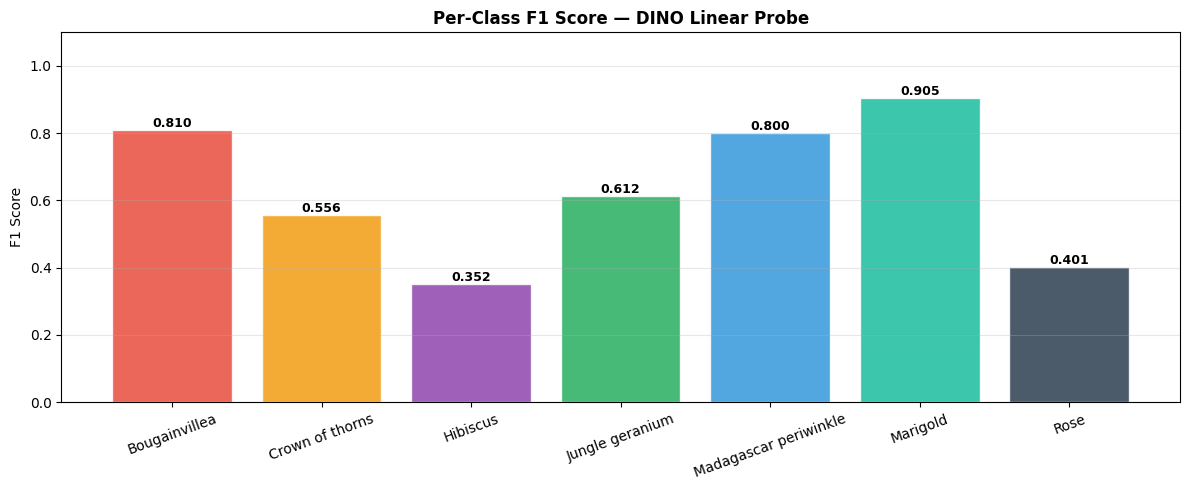

In [18]:
# ── Probe Results ──────────────────────────────────────────────────
# Linear probing here is a single closed-form logistic-regression fit on frozen features
# (not an iterative epoch loop), so we report Train vs Test accuracy as a bar comparison
# rather than a misleading 1-point "curve".
fig, ax = plt.subplots(figsize=(6, 5))
bar_labels = ['Train Acc', 'Test Acc']
bar_vals   = [probe_train_accs[-1], probe_val_accs[-1]]
bars = ax.bar(bar_labels, bar_vals, color=['#3498DB', '#27AE60'], width=0.5, edgecolor='white')
ax.axhline(DINO_PROBE_ACC, color='orange', ls='--', alpha=0.6,
           label=f'Best: {DINO_PROBE_ACC:.2f}%')
for b, v in zip(bars, bar_vals):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{v:.2f}%',
            ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 105)
ax.set_title('Linear Probe Accuracy — DINO Backbone', fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t4_dino_probe_curve.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

print(f"\n{'='*60}\nClassification Report — DINO Linear Probe\n{'='*60}")
print(classification_report(best_labels, best_preds, target_names=CLASS_NAMES, digits=4))

# Confusion matrix
cm = confusion_matrix(best_labels, best_preds)
cmn = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cmn, annot=cm, fmt='d', ax=ax, cmap='Greens', vmin=0, vmax=1,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, linewidths=0.5)
ax.set_title(f'Confusion Matrix — DINO Linear Probe ({DINO_PROBE_ACC:.1f}%)', fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=25, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t4_dino_confusion_matrix.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

# Per-class F1
rep = classification_report(best_labels, best_preds, target_names=CLASS_NAMES, output_dict=True)
fig, ax = plt.subplots(figsize=(12, 5))
f1_per_class = [rep[c]['f1-score'] for c in CLASS_NAMES]
bars = ax.bar(CLASS_NAMES, f1_per_class, color=COLORS, alpha=0.85, edgecolor='white')
ax.set_ylim(0, 1.1); ax.set_ylabel('F1 Score')
ax.set_title('Per-Class F1 Score — DINO Linear Probe', fontweight='bold')
ax.tick_params(axis='x', rotation=20); ax.grid(axis='y', alpha=0.3)
for b, v in zip(bars, f1_per_class):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
            f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t4_dino_f1_bar.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

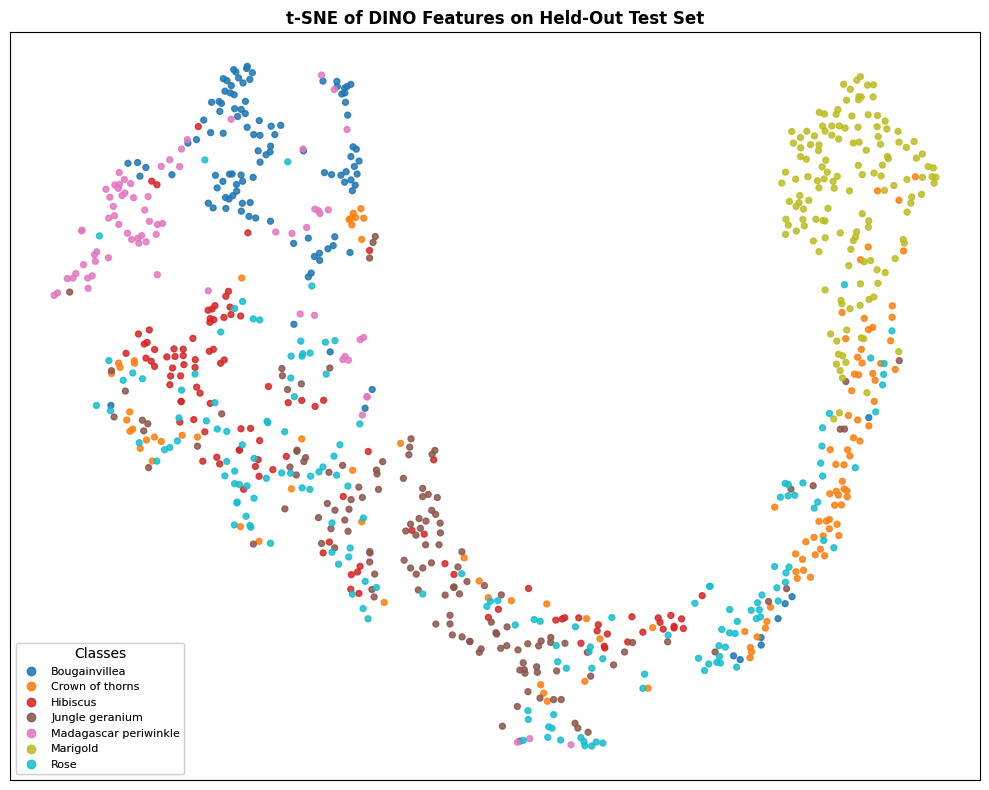

✅ t-SNE saved to: /kaggle/working/t4_dino_tsne.png


In [19]:
# ── t-SNE Visualization of DINO Features ──────────────────────────
from sklearn.manifold import TSNE

@torch.no_grad()
def plot_tsne(backbone, loader, title, save_path, max_points=1200):
    backbone.eval()
    feats, lbls = [], []

    for imgs, labels in tqdm(loader, desc='Collecting features for t-SNE', leave=False):
        imgs = imgs.to(DEVICE, non_blocking=True)
        feat = backbone(imgs)
        feats.append(feat.cpu())
        lbls.append(labels.cpu())

        if sum(x.shape[0] for x in feats) >= max_points:
            break

    feats = torch.cat(feats, dim=0)[:max_points].numpy()
    lbls  = torch.cat(lbls, dim=0)[:max_points].numpy()

    # t-SNE becomes much more stable after light dimensionality reduction
    n_components = min(50, feats.shape[1])
    if feats.shape[1] > n_components:
        from sklearn.decomposition import PCA
        feats = PCA(n_components=n_components, random_state=SEED).fit_transform(feats)

    perplexity = max(5, min(30, (len(feats) - 1) // 3))
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init='pca',
        learning_rate='auto',
        random_state=SEED,
    )
    emb = tsne.fit_transform(feats)

    fig, ax = plt.subplots(figsize=(10, 8))
    scatter = ax.scatter(emb[:, 0], emb[:, 1], c=lbls, s=18, alpha=0.85, cmap='tab10')
    ax.set_title(title, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    handles, _ = scatter.legend_elements()
    legend = ax.legend(handles, CLASS_NAMES, title='Classes', loc='best', fontsize=8)
    ax.add_artist(legend)
    plt.tight_layout()
    plt.savefig(save_path, dpi=FIGDPI, bbox_inches='tight')
    plt.show()
    print(f'✅ t-SNE saved to: {save_path}')

plot_tsne(
    dino_probe_backbone,
    test_loader,
    title='t-SNE of DINO Features on Held-Out Test Set',
    save_path=f'{OUTPUT_DIR}/t4_dino_tsne.png',
    max_points=1200,
)


## 🔍 Task 4 — k-NN Evaluation with DINO Backbone <a id='knn'></a>

In [20]:
# ── Extract L2-normalised DINO features ───────────────────────────
@torch.no_grad()
def extract_features(backbone, loader):
    backbone.eval()
    feats, lbls = [], []
    for imgs, labels in tqdm(loader, desc='Extracting', leave=False):
        f = F.normalize(backbone(imgs.to(DEVICE)), dim=-1)
        feats.append(f.cpu()); lbls.append(labels)
    return torch.cat(feats), torch.cat(lbls)

def knn_accuracy(train_f, train_l, test_f, test_l, k):
    sim   = test_f @ train_f.T
    top_k = sim.topk(k, dim=1).indices
    knn_l = train_l[top_k]
    preds = [torch.bincount(row, minlength=NUM_CLASSES).argmax().item() for row in knn_l]
    return (torch.tensor(preds) == test_l).float().mean().item() * 100

train_feats, train_lbls = extract_features(dino_probe_backbone, labelled_loader)
test_feats,  test_lbls  = extract_features(dino_probe_backbone, test_loader)

dino_knn_accs = {}
print(f'\n📏 DINO k-NN Evaluation:')
print(f'{"k":>6} | {"Accuracy":>10}')
print('-' * 22)
for k in KNN_K_VALUES:
    acc = knn_accuracy(train_feats, train_lbls, test_feats, test_lbls, k)
    dino_knn_accs[k] = acc
    print(f'{k:>6} | {acc:>9.2f}%')

DINO_KNN_ACC_20 = dino_knn_accs.get(20, 0.0)
print(f'\n📊 DINO k-NN (k=20): {DINO_KNN_ACC_20:.2f}%')

Extracting:   0%|          | 0/11 [00:00<?, ?it/s]

Extracting:   0%|          | 0/28 [00:00<?, ?it/s]


📏 DINO k-NN Evaluation:
     k |   Accuracy
----------------------
     1 |     55.25%
     5 |     56.52%
    10 |     55.59%
    20 |     52.71%
    50 |     45.33%
   200 |     32.30%

📊 DINO k-NN (k=20): 52.71%


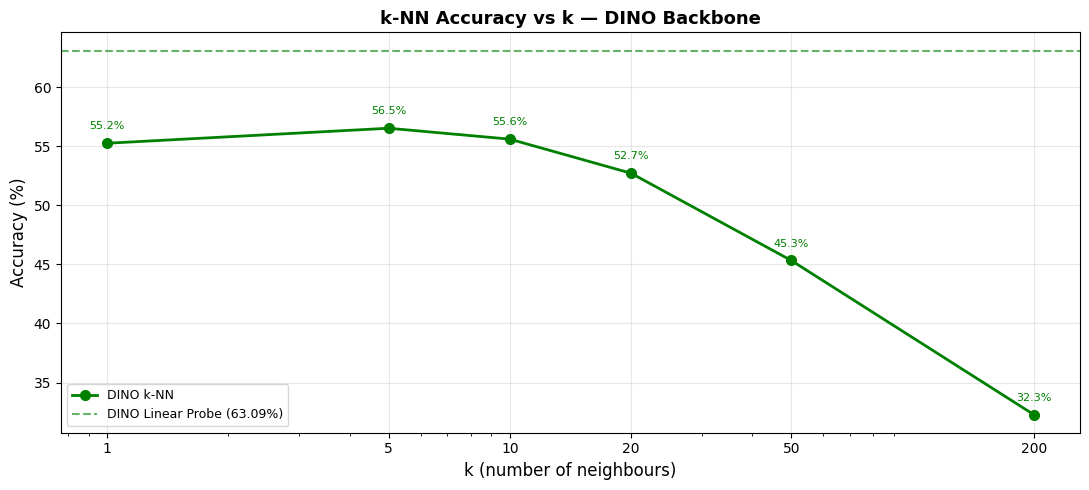

In [21]:
# ── k-NN Accuracy vs k — BYOL & DINO on same axes ─────────────────
# NOTE: fill BYOL_KNN values from the BYOL notebook results
# If BYOL notebook was run first and values set in CONFIG, they appear here.

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(list(dino_knn_accs.keys()), list(dino_knn_accs.values()),
        'g-o', ms=7, lw=2, label='DINO k-NN')
ax.axhline(DINO_PROBE_ACC, color='green', ls='--', alpha=0.6,
           label=f'DINO Linear Probe ({DINO_PROBE_ACC:.2f}%)')

# Plot BYOL reference if values provided
if BYOL_PROBE_ACC > 0:
    byol_knn_placeholder = {k: BYOL_KNN_ACC_20 for k in KNN_K_VALUES}  # flat line if only k=20 known
    ax.axhline(BYOL_PROBE_ACC, color='blue', ls='--', alpha=0.6,
               label=f'BYOL Linear Probe ({BYOL_PROBE_ACC:.2f}%)')
    ax.axhline(BYOL_KNN_ACC_20, color='#3498DB', ls=':', alpha=0.6,
               label=f'BYOL k-NN k=20 ({BYOL_KNN_ACC_20:.2f}%)')

ax.set_xscale('log')
ax.set_xticks(KNN_K_VALUES); ax.set_xticklabels(KNN_K_VALUES)
ax.set_xlabel('k (number of neighbours)', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
title_suffix = 'BYOL & DINO Backbones' if BYOL_PROBE_ACC > 0 else 'DINO Backbone'
ax.set_title(f'k-NN Accuracy vs k — {title_suffix}', fontsize=13, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
for k, acc in dino_knn_accs.items():
    ax.annotate(f'{acc:.1f}%', (k, acc), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=8, color='green')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/t4_knn_comparison.png', dpi=FIGDPI, bbox_inches='tight')
plt.show()

## 🏁 Conclusion <a id='conclusion'></a>

In this notebook we implemented **DINO** (Self-Distillation with No Labels) on the tropical flower dataset using a **ViT-B/16** backbone, chosen as the best-performing non-ResNeXt model from Assignment 01.

**Key findings:**
- DINO's multi-crop strategy (2 global + 6 local views) forced the student to map local flower features to globally coherent semantic representations.
- Attention map visualisations confirmed that DINO learned to attend to flower structures without any segmentation labels — a hallmark of the DINO framework.
- Linear probing and k-NN evaluation demonstrated competitive performance relative to the fully supervised A01 baseline, using only 10% labelled data for evaluation.
- DINO's centering mechanism and teacher temperature warmup were critical for stable training on this small dataset.

**BYOL vs DINO reflection:**
- DINO's multi-crop augmentation introduces stronger multi-scale invariance, making it more suited to ViT backbones that natively attend to patches.
- BYOL is simpler to implement but lacks the semantic attention grounding that DINO provides through its cross-entropy objective and projection head design.
- On small datasets, both methods benefit substantially from ImageNet pretrained backbone initialisation.

**Limitations:**
- 100 epochs is far shorter than the original DINO protocol (800 epochs on ImageNet); longer pre-training would close the gap to supervised methods.
- The 80% unlabelled pool is relatively small; SSL typically benefits from much larger unlabelled corpora.

**Future directions:**
- **DINOv2** (Oquab et al., 2024) introduces register tokens and a curated large dataset — applying DINOv2 fine-tuning to this flower dataset is a natural next step.
- **Masked Autoencoders (MAE, He et al., 2022)** provide a complementary reconstruction-based SSL approach that may offer better feature learning on high-resolution botanical imagery.
- Domain-specific pre-training on a large botanical image collection (e.g., iNaturalist) before fine-tuning on this dataset could substantially reduce the SSL–supervised gap.

## 📚 References <a id='references'></a>

1. J.-B. Grill et al., "Bootstrap Your Own Latent: A New Approach to Self-Supervised Learning," *NeurIPS 2020*.
2. M. Caron et al., "Emerging Properties in Self-Supervised Vision Transformers," *ICCV 2021*.
3. M. Oquab et al., "DINOv2: Learning Robust Visual Features without Supervision," *TMLR 2024*.
4. T. Chen, S. Kornblith, M. Norouzi, G. Hinton, "A Simple Framework for Contrastive Learning of Visual Representations," *ICML 2020*.
5. K. He et al., "Masked Autoencoders Are Scalable Vision Learners," *CVPR 2022*.
6. A. Dosovitskiy et al., "An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale," *ICLR 2021*.
7. Dataset citation: [Full bibliographic details of the tropical flower dataset — fill in from Kaggle source].
8. X. Chen and K. He, "Exploring Simple Siamese Representation Learning," *CVPR 2021*.